![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 3. Interferometers I - MZI


Today we will work on the design and modeling of an **Mach-Zenhder Interferometer (MZI)** used in integrated photonic circuits. We will perform simulations that will allow us to understand how it operates.


## 0.1 General libraries

In [1]:
import gdsfactory as gf
import jax
import jax.example_libraries.optimizers as opt
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
from scipy.signal import find_peaks, peak_prominences # extra


import numpy as np
import sax
from gdsfactory.generic_tech import get_generic_pdk
from scipy import constants
from scipy.constants import c
from scipy.interpolate import interp1d

import gplugins.sax as gs
from gplugins.common.config import PATH

C:\Users\Nayan\AppData\Local\Temp\ipykernel_22484\1534690884.py:12: DeprecationWarning: The 'gdsfactory.generic_tech' module is deprecated and will be removed in a future version. Please update your imports to use 'gdsfactory.gpdk' instead:
  from gdsfactory.gpdk import LAYER, LAYER_STACK, get_generic_pdk
Or for submodules:
  from gdsfactory.gpdk.layer_map import LAYER
  from gdsfactory.gpdk.layer_stack import LAYER_STACK
  from gdsfactory.generic_tech import get_generic_pdk


## 1. MZI modeling
Let's compute the transfer function of a MZI

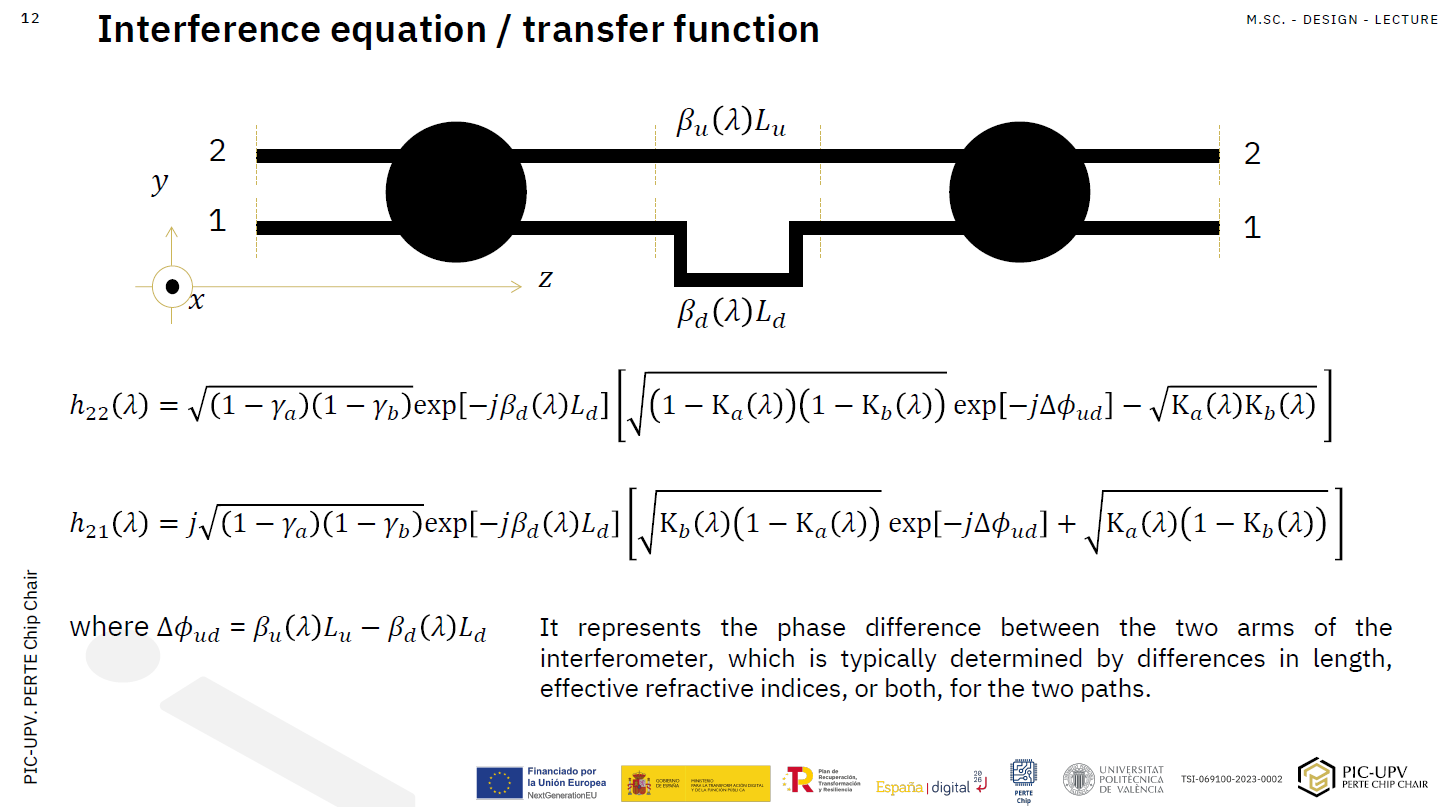

In [2]:
# Ctrl+ç for commenting blocks

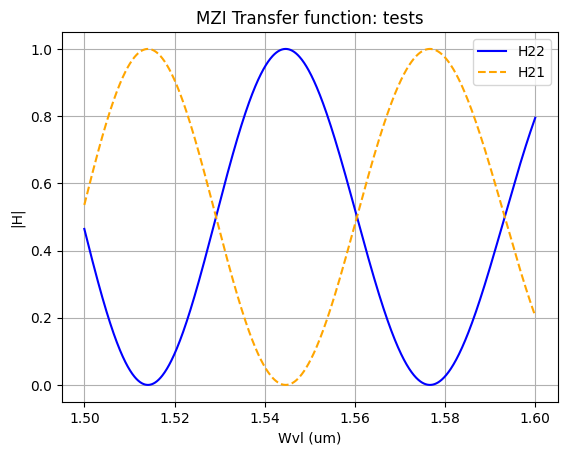

In [3]:
### Waveguides configuration ###


## Propagation parameters

# SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0] # wavelength
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) down

## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Water.txt', skiprows=1, delimiter='\t')
SiN_air = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 25; # um
Ld = 5; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
gamma_a = 0; #null excess loss
gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

# MZI transfer function (h22 & h21)

#  h_22(wvl)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

#  h_21(wvl)
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

# to get the transmission we do the modulus square 
H21 = np.abs(h_21) ** 2
H22 = np.abs(h_22) ** 2

# Plot
color = cm.rainbow(np.linspace(0, 1, 10))

plt.plot(wvl, H22, linestyle='-', color='blue', label='H22')
plt.plot(wvl, H21, linestyle='--', color='orange', label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('MZI Transfer function: tests')
plt.legend()
plt.grid(True)

plt.show()

### **Assesment 1.** Please, provide one example of each one of the configurations studied during MZI lecture:
1. Balenced configuration
2. Unbalanced configuration
  1.   Phase difference
  2.   Delay imbalance

##### Effective indices of the materials

<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Nayan\AppData\Local\Temp\ipykernel_22484\1355448764.py:20: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (um)')


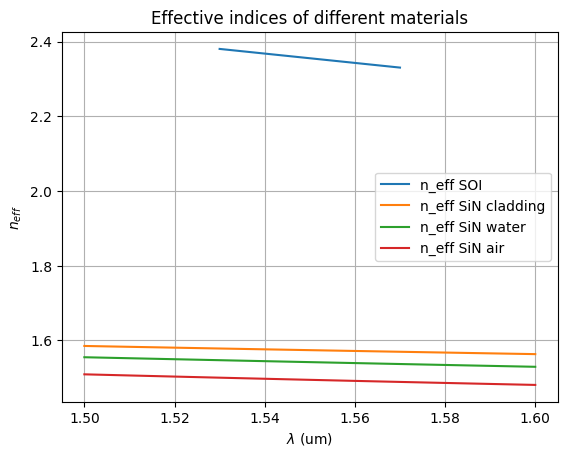

In [4]:
# SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Water.txt', skiprows=1, delimiter='\t')
SiN_air = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl_SOI = SOI[:,0]
neff_SOI = SOI[:,3]
wvl_SiN = SiN_clad[:,0]
neff_SiN_clad = SiN_clad[:,3]
neff_SiN_wat = SiN_wat[:,3]
neff_SiN_air = SiN_air[:,3]

plt.plot(wvl_SOI, neff_SOI, label='n_eff SOI')
plt.plot(wvl_SiN, neff_SiN_clad, label='n_eff SiN cladding')
plt.plot(wvl_SiN, neff_SiN_wat, label='n_eff SiN water')
plt.plot(wvl_SiN, neff_SiN_air, label='n_eff SiN air')
plt.xlabel('$\lambda$ (um)')
plt.ylabel('$n_{eff}$')
plt.title('Effective indices of different materials')
plt.legend()
plt.grid(True)

plt.show()

##### 1. Balanced configuration 

In [5]:
# BALANCED CONFIGURATION: beta_u = beta_d L_u = L_d

## Propagation parameters

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 25; # um
Ld = 25; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
gamma_a = 0; #null excess loss
gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

# MZI transfer function (h22 & h21)

#  h_22(wvl)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

#  h_21(wvl)
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

# to get the transmission we do the modulus square 
H21_bal = np.abs(h_21) ** 2
H22_bal = np.abs(h_22) ** 2


##### 2. Unbalanced configuration
##### 2.1. Delay imbalance

In [6]:
# DELAY IMBALANCE: beta_u = beta_d, L_u =! L_d

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 25; # um
Ld = 5; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
gamma_a = 0; #null excess loss
gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

# MZI transfer function (h22 & h21)

#  h_22(wvl)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

#  h_21(wvl)
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

# to get the transmission we do the modulus square 
H21_unb_delay = np.abs(h_21) ** 2
H22_unb_delay = np.abs(h_22) ** 2

##### 2.2. Phase difference

In order to appreciate the difference of beta we must work in very big path difference (such as spirals of the order of cm). Increasing the path difference also increases oscillations so in order to observe the results, we also have to zoom in the wavelength range. 

In [7]:
# PHASE DIFFERENCE: different beta, same L

## Propagation parameters

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_air[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 1000; # um
Ld = 1000; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
gamma_a = 0; #null excess loss
gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

# MZI transfer function (h22 & h21)

#  h_22(wvl)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

#  h_21(wvl)
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

# to get the transmission we do the modulus square 
H21_unb_phase = np.abs(h_21) ** 2
H22_unb_phase = np.abs(h_22) ** 2

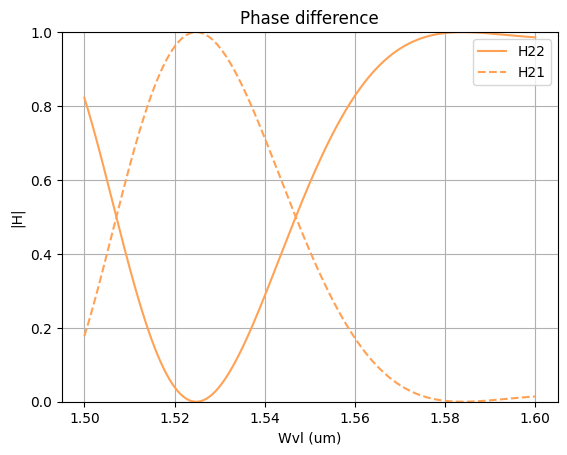

In [8]:
plt.plot(wvl, H22_unb_phase, linestyle='-', color=color[7], label='H22')
plt.plot(wvl, H21_unb_phase, linestyle='--', color=color[7], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.ylim(0,1)
plt.title('Phase difference')
plt.legend()
plt.grid(True)

bigger L generates bigger oscillations

##### 2.3. Delay imbalance and Phase difference


In [9]:
# COMPLETE IMBALANCE: different beta and L

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 900; # um
Ld = 1000; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
gamma_a = 0; #null excess loss
gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

# MZI transfer function (h22 & h21)

#  h_22(wvl)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

#  h_21(wvl)
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

# to get the transmission we do the modulus square 
H21_unb_delpha = np.abs(h_21) ** 2
H22_unb_delpha = np.abs(h_22) ** 2


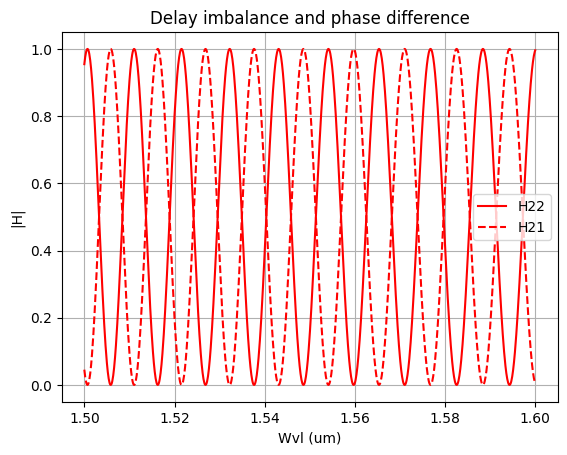

In [10]:
plt.plot(wvl, H22_unb_delpha, linestyle='-', color=color[9], label='H22')
plt.plot(wvl, H21_unb_delpha, linestyle='--', color=color[9], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
# plt.xlim(1.54, 1.56)
plt.title('Delay imbalance and phase difference')
plt.legend()
plt.grid(True)

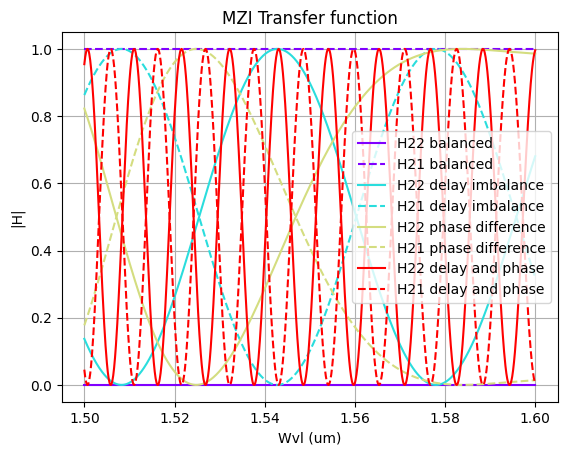

In [11]:
color = cm.rainbow(np.linspace(0, 1, 10))

plt.plot(wvl, H22_bal, linestyle='-', color=color[0], label='H22 balanced')
plt.plot(wvl, H21_bal, linestyle='--', color=color[0], label='H21 balanced')
plt.plot(wvl, H22_unb_delay, linestyle='-', color=color[3], label='H22 delay imbalance')
plt.plot(wvl, H21_unb_delay, linestyle='--', color=color[3], label='H21 delay imbalance')
plt.plot(wvl, H22_unb_phase, linestyle='-', color=color[6], label='H22 phase difference')
plt.plot(wvl, H21_unb_phase, linestyle='--', color=color[6], label='H21 phase difference')
plt.plot(wvl, H22_unb_delpha, linestyle='-', color=color[9], label='H22 delay and phase')
plt.plot(wvl, H21_unb_delpha, linestyle='--', color=color[9], label='H21 delay and phase')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
# plt.xlim(1.5, 1.51)
plt.title('MZI Transfer function')
plt.legend()
plt.grid(True)

plt.show()

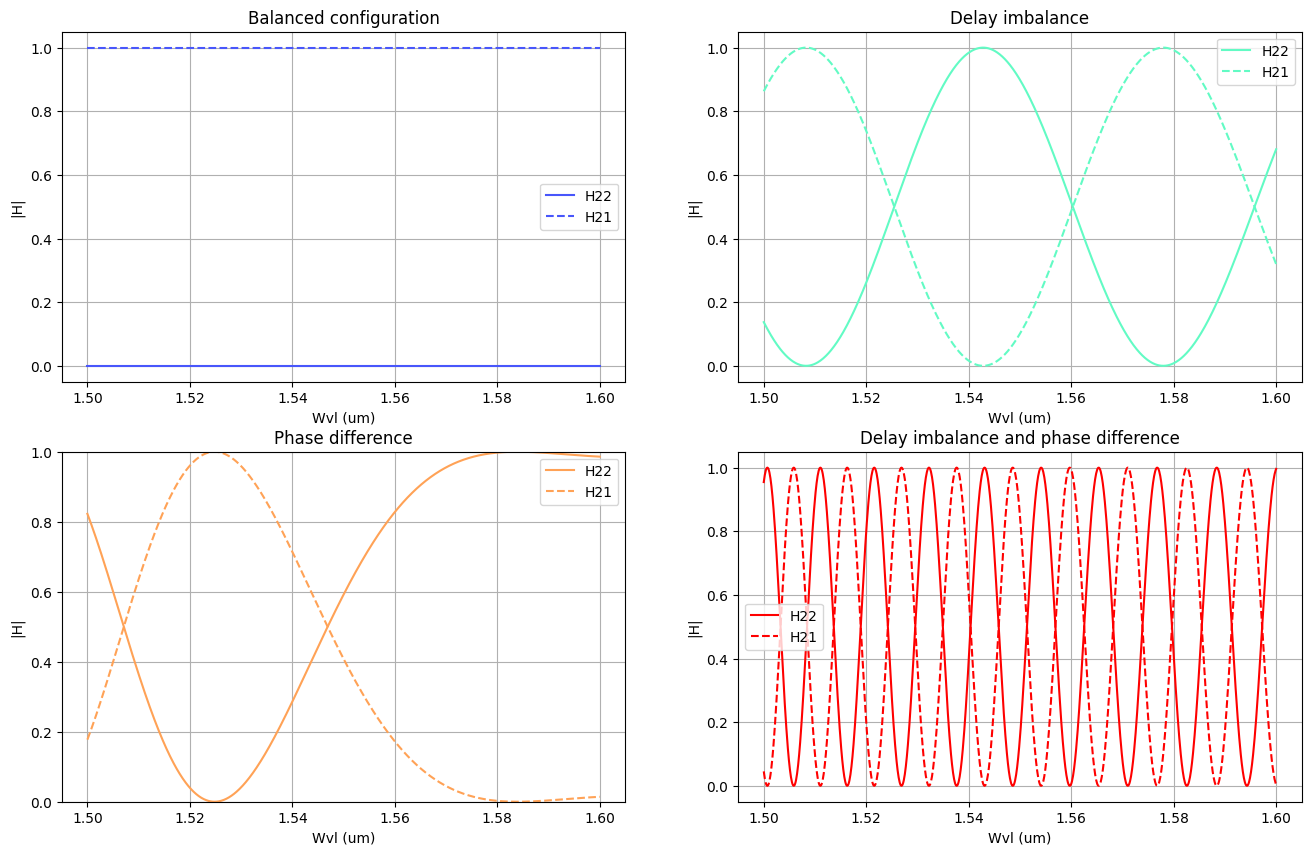

In [12]:
plt.figure(figsize=(16,10))

plt.subplot(2,2,1)
plt.plot(wvl, H22_bal, linestyle='-', color=color[1], label='H22')
plt.plot(wvl, H21_bal, linestyle='--', color=color[1], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('Balanced configuration')
plt.legend()
plt.grid(True)

plt.subplot(2,2,2)
plt.plot(wvl, H22_unb_delay, linestyle='-', color=color[4], label='H22')
plt.plot(wvl, H21_unb_delay, linestyle='--', color=color[4], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('Delay imbalance')
plt.legend()
plt.grid(True)

plt.subplot(2,2,3)
plt.plot(wvl, H22_unb_phase, linestyle='-', color=color[7], label='H22')
plt.plot(wvl, H21_unb_phase, linestyle='--', color=color[7], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.ylim(0,1)
plt.title('Phase difference')
plt.legend()
plt.grid(True)

plt.subplot(2,2,4)
plt.plot(wvl, H22_unb_delpha, linestyle='-', color=color[9], label='H22')
plt.plot(wvl, H21_unb_delpha, linestyle='--', color=color[9], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('Delay imbalance and phase difference')
plt.legend()
plt.grid(True)

##### Propagation loss $\alpha \neq 0$
Same loss in both arms

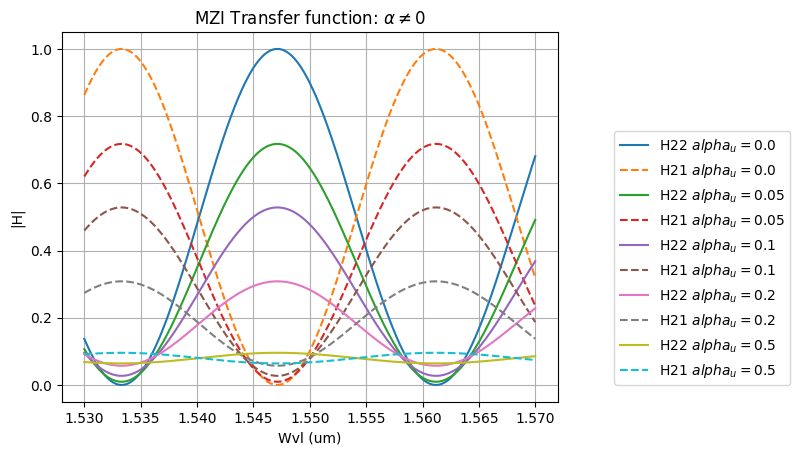

In [14]:
### Waveguides configuration ###


## Propagation parameters

# SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

alpha_array = np.array([[0,0], [0.05, 0.05], [0.1, 0.1], [0.2, 0.2], [0.5, 0.5]])
for alphau, alphad in alpha_array:
    # Propagation loss
    # alphau = alphau #losless case [dB/um]
    # alphad = 0; #losless case [dB/um]
    alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
    alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

    # Path length
    Lu = 25; # um
    Ld = 5; # um

    betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
    betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

    Delta_phi_ud = betau*Lu - betad*Ld

    ### Couplers configuration ###
    # Excess loss
    gamma_a = 0; #null excess loss
    gamma_b = 0; #null excess loss

    # Coupling constant
    K_a = np.full(wvl.shape, 0.5)
    K_b = np.full(wvl.shape, 0.5)

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    # to get the transmission we do the modulus square 
    H21 = np.abs(h_21) ** 2
    H22 = np.abs(h_22) ** 2

    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))

    plt.plot(wvl, H22, linestyle='-', label=f'H22 $alpha_u={alphau}$')
    plt.plot(wvl, H21, linestyle='--', label=f'H21 $alpha_u={alphad}$')



plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title(r'MZI Transfer function: $\alpha \neq 0$')
plt.legend(bbox_to_anchor=(1.1, 0.75))
# plt.xlim(1.5, 1.51)
# plt.ylim(0,1)1
plt.grid(True)

plt.show()

##### Propagation loss $\alpha \neq 0$
Different loss in each arm

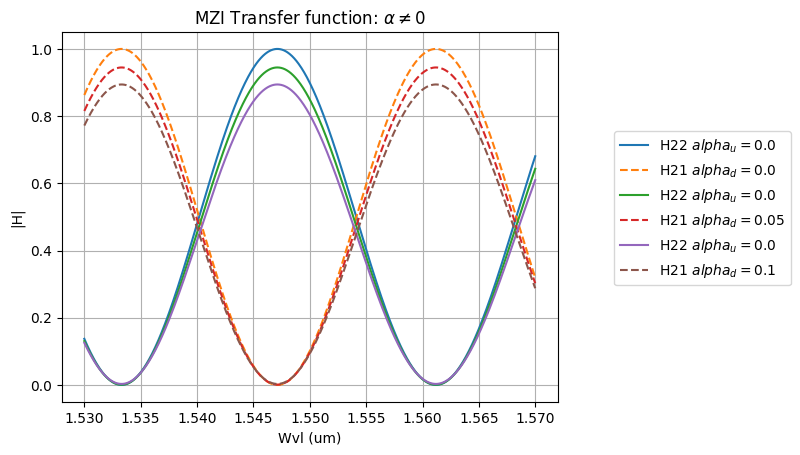

In [15]:
### Waveguides configuration ###


## Propagation parameters

# SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

alpha_array = np.array([[0,0], [0, 0.05], [0, 0.1]])
for alphau, alphad in alpha_array:
    # Propagation loss
    # alphau = alphau #losless case [dB/um]
    # alphad = 0; #losless case [dB/um]
    alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
    alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

    # Path length
    Lu = 25; # um
    Ld = 5; # um

    betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
    betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

    Delta_phi_ud = betau*Lu - betad*Ld

    ### Couplers configuration ###
    # Excess loss
    gamma_a = 0; #null excess loss
    gamma_b = 0; #null excess loss

    # Coupling constant
    K_a = np.full(wvl.shape, 0.5)
    K_b = np.full(wvl.shape, 0.5)

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    # to get the transmission we do the modulus square 
    H21 = np.abs(h_21) ** 2
    H22 = np.abs(h_22) ** 2

    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))

    plt.plot(wvl, H22, linestyle='-', label=f'H22 $alpha_u={alphau}$')
    plt.plot(wvl, H21, linestyle='--', label=f'H21 $alpha_d={alphad}$')



plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title(r'MZI Transfer function: $\alpha \neq 0$')
plt.legend(bbox_to_anchor=(1.1, 0.75))
# plt.xlim(1.5, 1.51)
# plt.ylim(0,1)1
plt.grid(True)

plt.show()

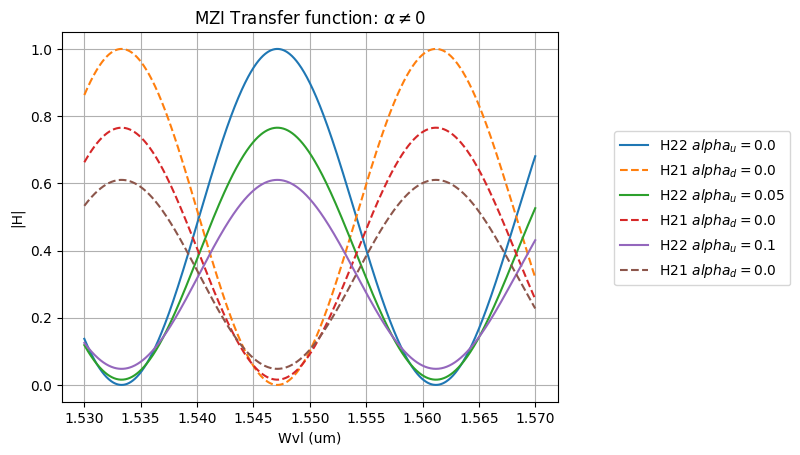

In [16]:
### Waveguides configuration ###


## Propagation parameters

# SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

alpha_array = np.array([[0,0], [0.05, 0], [0.1, 0]])
for alphau, alphad in alpha_array:
    # Propagation loss
    # alphau = alphau #losless case [dB/um]
    # alphad = 0; #losless case [dB/um]
    alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
    alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

    # Path length
    Lu = 25; # um
    Ld = 5; # um

    betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
    betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

    Delta_phi_ud = betau*Lu - betad*Ld

    ### Couplers configuration ###
    # Excess loss
    gamma_a = 0; #null excess loss
    gamma_b = 0; #null excess loss

    # Coupling constant
    K_a = np.full(wvl.shape, 0.5)
    K_b = np.full(wvl.shape, 0.5)

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    # to get the transmission we do the modulus square 
    H21 = np.abs(h_21) ** 2
    H22 = np.abs(h_22) ** 2

    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))

    plt.plot(wvl, H22, linestyle='-', label=f'H22 $alpha_u={alphau}$')
    plt.plot(wvl, H21, linestyle='--', label=f'H21 $alpha_d={alphad}$')



plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title(r'MZI Transfer function: $\alpha \neq 0$')
plt.legend(bbox_to_anchor=(1.1, 0.75))
# plt.xlim(1.5, 1.51)
# plt.ylim(0,1)1
plt.grid(True)

plt.show()

##### Excess loss $\gamma \neq 0$

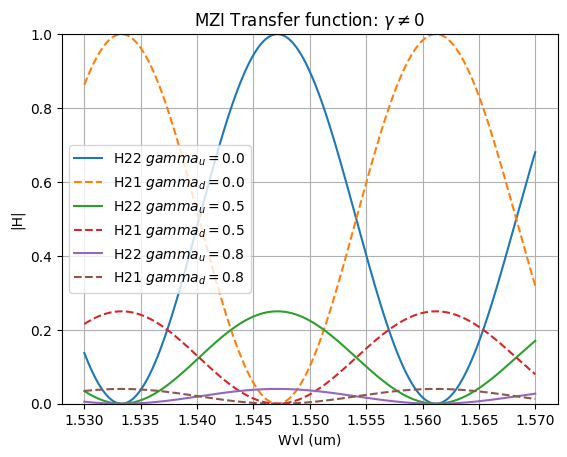

In [16]:
### Waveguides configuration ###


## Propagation parameters

# SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 25; # um
Ld = 5; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
# gamma_a = 0; #null excess loss
# gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

gamma_array = np.array([[0,0], [0.5, 0.5], [0.8, 0.8]])
for gamma_a, gamma_b in gamma_array:

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    # to get the transmission we do the modulus square 
    H21 = np.abs(h_21) ** 2
    H22 = np.abs(h_22) ** 2

    plt.plot(wvl, H22, linestyle='-', label=f'H22 $gamma_u={gamma_a}$')
    plt.plot(wvl, H21, linestyle='--', label=f'H21 $gamma_d={gamma_b}$')


plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title(r'MZI Transfer function: $\gamma \neq 0$')
plt.legend()
# plt.xlim(1.5, 1.51)
plt.ylim(0,1)
plt.grid(True)

plt.show()

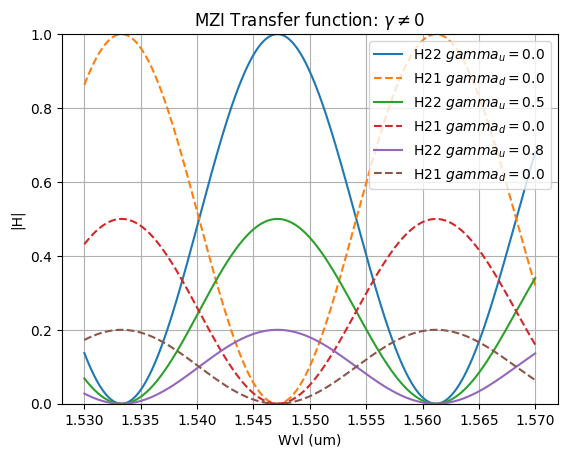

In [17]:
### Waveguides configuration ###


## Propagation parameters

# SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 25; # um
Ld = 5; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
# gamma_a = 0; #null excess loss
# gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

gamma_array = np.array([[0,0], [0.5, 0], [0.8, 0]])
for gamma_a, gamma_b in gamma_array:

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    # to get the transmission we do the modulus square 
    H21 = np.abs(h_21) ** 2
    H22 = np.abs(h_22) ** 2

    plt.plot(wvl, H22, linestyle='-', label=f'H22 $gamma_u={gamma_a}$')
    plt.plot(wvl, H21, linestyle='--', label=f'H21 $gamma_d={gamma_b}$')


plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title(r'MZI Transfer function: $\gamma \neq 0$')
plt.legend()
# plt.xlim(1.5, 1.51)
plt.ylim(0,1)
plt.grid(True)

plt.show()

##### Propagation and excess loss (?) $\alpha, \gamma \neq 0$

**Assesment 2.** Taking into account the n_{eff} values for the SOI cross-section, what would be the path difference ($\Delta L$ = $L_u$ - $L_d$) needed to obtain a Free Spectral Range of 40 nm? Introduce the obtained value in the model to check the MZI response. Hint: We assume 1550 nm as the central design wavelength ($\lambda _0$=1550 nm).

We calculate the group index from code of the Lab 0.3 Ring resonator

In [19]:
# Effective index at 1550 nm
lambda0 = 1.55 # um
idx = np.argmin(np.abs(wvl - lambda0))
neff_1550 = neffu[idx]

print(f'n_eff at 1550 nm = {neff_1550:.5f}')

# Numerical derivative of effective index
dneff_dlambda = np.gradient(neffu, wvl)

# Calculate group index
ng = neffu - wvl * dneff_dlambda

# Group index at 1550 nm
ng_1550 = ng[idx]

print(f'n_g at 1550 nm = {ng_1550:.5f}')

FSR = 0.04 # um
DeltaL = lambda0**2 / (ng_1550*FSR)
print(f'DeltaL: {DeltaL} um') 

n_eff at 1550 nm = 2.35580
n_g at 1550 nm = 4.29327
DeltaL: 13.989931688102228 um


In [20]:
# DELAY IMBALANCE: beta_u = beta_d, L_u =! L_d

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 50+DeltaL; # um
Ld = 50; # um

betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

Delta_phi_ud = betau*Lu - betad*Ld

### Couplers configuration ###
# Excess loss
gamma_a = 0; #null excess loss
gamma_b = 0; #null excess loss

# Coupling constant
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)

# MZI transfer function (h22 & h21)

#  h_22(wvl)
h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

#  h_21(wvl)
h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

# to get the transmission we do the modulus square 
H21_unb_delay = np.abs(h_21) ** 2
H22_unb_delay = np.abs(h_22) ** 2

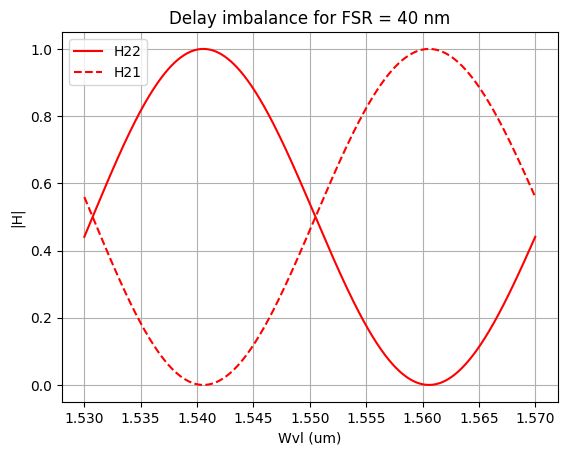

In [21]:
plt.plot(wvl, H22_unb_delay, linestyle='-', color=color[9], label='H22')
plt.plot(wvl, H21_unb_delay, linestyle='--', color=color[9], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
# plt.xlim(1.54, 1.56)
plt.title('Delay imbalance for FSR = 40 nm')
plt.legend()
plt.grid(True)

the FSR of a Mach Zender is the distance between maximum or minimum peaks. In this case, since the wavelength range is restricted (equal to the FSR), it is hard to visually determine the distance between peaks. We will calculate the distance between peak and dip and multiply by two. 

In [19]:
peaks = find_peaks(H22_unb_delay)[0]
dips = find_peaks(-H22_unb_delay)[0]
wvl_peaks = wvl[peaks]
wvl_dips = wvl[dips]
FSR = 2*(wvl_dips-wvl_peaks)[0]
print(f'FSR: {FSR*1e3:.4f}nm')

FSR: -27.6276nm


## 2. MZI simulation implemented with SAX
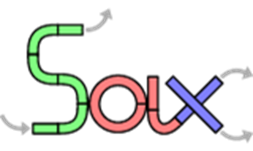

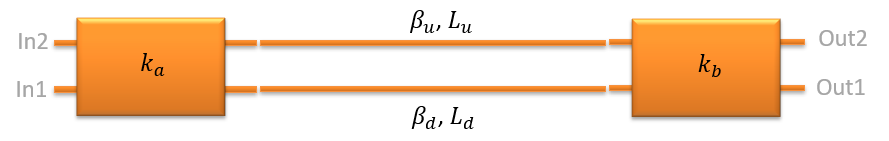


### 2.1 Components S matrix


In [20]:
# Waveguide Model

def waveguide(wl=1.55, neff=1.6072, length=10.0, loss=0.0) -> sax.SDict:
    phase = 2 * jnp.pi * neff * length / wl
    transmission = 10 ** (-loss * length / 20) * jnp.exp(1j * phase) # loss(dB/um)
    wg_dict = sax.reciprocal(
        {
            ("in0", "out0"): transmission, # here we define the transmisssion
        }
    )
    return wg_dict


# Coupler Model

def coupler(coupling=0.5) -> sax.SDict:
    kappa = coupling**0.5
    tau = (1 - coupling) ** 0.5
    coupler_dict = sax.reciprocal(
        {
            ("in0", "out0"): tau,
            ("in0", "out1"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out0"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out1"): tau,
        }
    )
    return coupler_dict

### 2.2 MZI SAX Circuit Model

In [21]:
# MZI

mzi, info = sax.circuit(
    netlist={
        "instances": {
            "coup_a": "coupler",
            "wvg_u": "waveguide",
            "wvg_d": "waveguide",
            "coup_b": "coupler",
        },
        "connections": {
            "coup_a,out0": "wvg_d,in0",
            "wvg_d,out0": "coup_b,in0",
            "coup_a,out1": "wvg_u,in0",
            "wvg_u,out0": "coup_b,in1",
        },
        "ports": {
            "in0": "coup_a,in0",
            "in1": "coup_a,in1",
            "out0": "coup_b,out0",
            "out1": "coup_b,out1",
        },
    },
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)


### 2.3. MZI Modeling
**Assesment 3**: Now, we are going to implement the design parameters in the MZI model developed in SAX and compare the response obtained with that simulated by mathematical formulation.

This will help us to identify any error in the definition of the SAX model single components.

In order to implement the SAX model, take as example the following lines:

    mzi_test = mzi(wl=wl,
                coup_a = ...
                wvg_d={"length": l_d, "neff": ...},
                wvg_u={"length": l_u, "neff": ...},
                coup_b = ... )

    H00 = mzi_test["in0", "out0"]

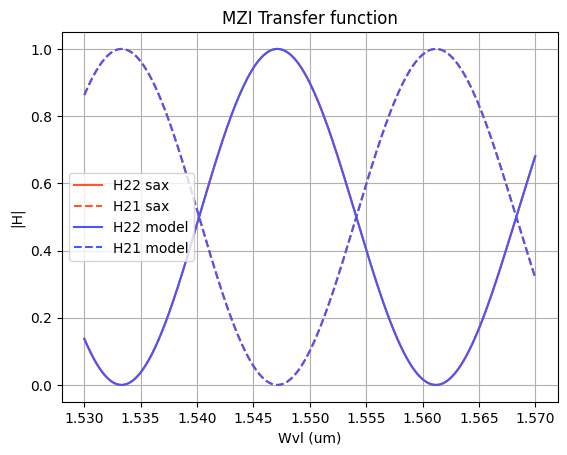

In [ ]:
wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

# Propagation loss
alphau = 0 #losless case [dB/um]
alphad = 0; #losless case [dB/um]
alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

# Path length
Lu = 25; # um
Ld = 5; # um

mzi_test = mzi(wl=wvl,
            coup_a={"coupling":K_a}, # same for all couplers
            wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
            coup_b={"coupling":K_b},
            )

h00 = mzi_test["in0", "out0"]
h01 = mzi_test["in0", "out1"]
h11 = mzi_test["in1", "out1"]
h10 = mzi_test["in1", "out0"]


# Plot
plt.figure()
plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"H22 sax")
plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"H21 sax")
plt.plot(wvl, H22_unb_delay, linestyle='-', color=color[1], label='H22 model')
plt.plot(wvl, H21_unb_delay, linestyle='--', color=color[1], label='H21 model')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('MZI Transfer function')
plt.legend()
plt.grid(True)
plt.show()



**Assessment 4.** Designing an MZI for filtering at a specific wavelength. Calculate and adjust the arm lengths to configure the MZI to have a maximum transmission at 1550 nm.

$\phi = \beta \Delta L = \frac{2\pi n_{eff} }{\lambda} \Delta L= 2 \pi m$ --> $\Delta L = m \lambda / n_{eff}$

$FSR = \frac{\lambda^2}{n_g \Delta L}$ --> $\Delta L = \frac{\lambda^2}{n_g FSR}$


In [84]:
# Effective index at 1550 nm
lambda0 = 1.55 # um

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

idx = np.argmin(np.abs(wvl - lambda0))
neff_1550 = neffu[idx]

print(f'n_eff at 1550 nm = {neff_1550:.5f}')

# Numerical derivative of effective index
dneff_dlambda = np.gradient(neffu, wvl)

# Calculate group index
ng = neffu - wvl * dneff_dlambda

# Group index at 1550 nm
ng_1550 = ng[idx]

print(f'n_g at 1550 nm = {ng_1550:.5f}')

m = 10 # order of resonance
# FSR = lambda0*neff_1550*m/ng_1550 # um
DeltaL = lambda0*m/neff_1550
print(f'DeltaL: {DeltaL} um') 

n_eff at 1550 nm = 2.35580
n_g at 1550 nm = 4.29327
DeltaL: 6.579519795086878 um


In [85]:
FSR = lambda0**2 / (ng_1550*DeltaL)
print(FSR)

0.08505138444023788


In [86]:
L = 100 # um

mzi_ass4 = mzi(wl=wvl,
            coup_a={"coupling":K_a},
            wvg_u={"wl":wvl, "neff":neffu, "length": L, "loss":alphau},
            wvg_d={"wl":wvl, "neff":neffd, "length": L+DeltaL, "loss":alphad},
            coup_b={"coupling":K_b},
            )

# h00 = mzi_ass4["in0", "out0"]
# h01 = mzi_ass4["in0", "out1"]
h11 = mzi_ass4["in1", "out1"]
h10 = mzi_ass4["in1", "out0"]
H11 = np.abs(h11)**2
H10 = np.abs(h10)**2
H11_db = 10*np.log10(H11)
H10_db = 10*np.log10(H10)


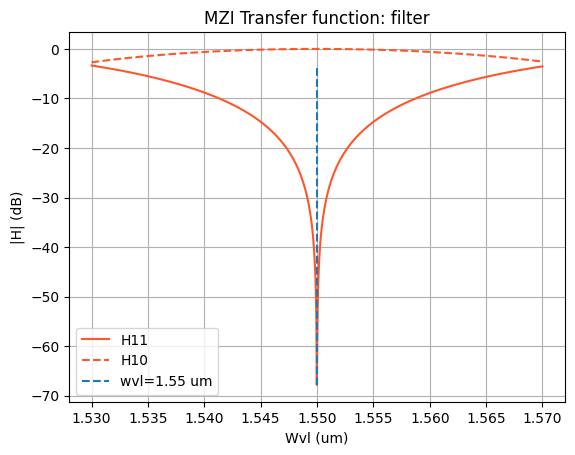

In [87]:
# Plot
plt.figure()
plt.plot(wvl, H11_db, linestyle="-", color=color[8], label=f"H11")
plt.plot(wvl, H10_db, linestyle="--", color=color[8], label=f"H10")
plt.vlines(1.55, np.min(H11_db), np.max(H11_db), linestyle='--', label='wvl=1.55 um')
plt.xlabel('Wvl (um)')
plt.ylabel('|H| (dB)')
plt.title('MZI Transfer function: filter')
plt.legend()
plt.grid(True)
plt.show()

**Assessment 5.** Let's see how the response of the MZI variates with the effective index. Vary the effective index of one of the arms and analyze how the spectrum shifts. To do this, you can use the data provided in the .txt files entitled ‘SiN’.
Can you give an example of an application where this configuration is used?

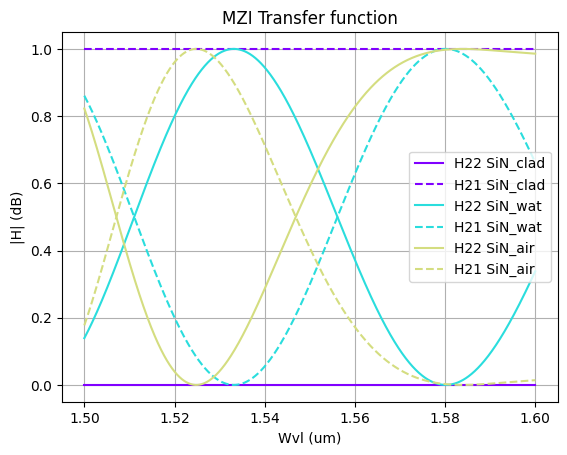

In [ ]:
# PHASE DIFFERENCE: different beta, same L

materials = np.array([SiN_clad, SiN_wat, SiN_air])
labels = np.array(['SiN_clad', 'SiN_wat', 'SiN_air'])


## Propagation parameters

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3]
for i in range(len(materials)):
    neffd0 = materials[i][:, 3]   

    interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
    interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
    wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
    neffu = interp_neffu(wvl)
    neffd = interp_neffd(wvl)

    # Propagation loss
    alphau = 0 #losless case [dB/um]
    alphad = 0; #losless case [dB/um]
    alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
    alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

    # Path length
    Lu = 1000; # um
    Ld = 1000; # um

    betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
    betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

    Delta_phi_ud = betau*Lu - betad*Ld

    ### Couplers configuration ###
    # Excess loss
    gamma_a = 0; #null excess loss
    gamma_b = 0; #null excess loss

    # Coupling constant
    K_a = np.full(wvl.shape, 0.5)
    K_b = np.full(wvl.shape, 0.5)

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    # to get the transmission we do the modulus square 
    H21_unb_phase = np.abs(h_21) ** 2
    H22_unb_phase = np.abs(h_22) ** 2

    H21_unb_phase_db = 10*np.log10(H21_unb_phase+1e-6)
    H22_unb_phase_db = 10*np.log10(H22_unb_phase+1e-6)

    plt.plot(wvl, H22_unb_phase_db, linestyle='-', color=color[3*i], label=f'H22 {labels[i]}')
    plt.plot(wvl, H21_unb_phase_db, linestyle='--', color=color[3*i], label=f'H21 {labels[i]}')
plt.xlabel('Wvl (um)')
plt.ylabel('|H| (dB)')
# plt.xlim(1.5, 1.51)
plt.title('MZI Transfer function')
plt.legend()
plt.grid(True)

plt.show()

**Assessment 6.** Explore how cascading two MZIs affects the transmission spectrum. To do so, design a system in which two MZIs are cascaded. Simulate and observe the spectrum, explaining how the transmission peaks behave.

In [94]:
# MZI

mzi_2, info = sax.circuit(
    netlist={
        "instances": {
            "coup_a": "coupler",
            "wvg_u1": "waveguide",
            "wvg_d1": "waveguide",
            "coup_b": "coupler",
            "wvg_u2": "waveguide",
            "wvg_d2": "waveguide",  
            "coup_c": "coupler",
            "wvg_u3": "waveguide",
            "wvg_d3": "waveguide",
            "coup_d": "coupler",
        
        },
        "connections": {
            "coup_a,out0": "wvg_d1,in0",
            "coup_a,out1": "wvg_u1,in0",
            "wvg_d1,out0": "coup_b,in0",
            "wvg_u1,out0": "coup_b,in1",

            "coup_b,out0": "wvg_d2,in0",
            "coup_b,out1": "wvg_u2,in0",
            "wvg_d2,out0": "coup_c,in0",
            "wvg_u2,out0": "coup_c,in1",

            "coup_c,out0": "wvg_d3,in0",
            "coup_c,out1": "wvg_u3,in0",
            "wvg_d3,out0": "coup_d,in0",
            "wvg_u3,out0": "coup_d,in1",           
        },
        "ports": {
            "in0": "coup_a,in0",
            "in1": "coup_a,in1",
            "out0": "coup_d,out0",
            "out1": "coup_d,out1",
        },
    },
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)


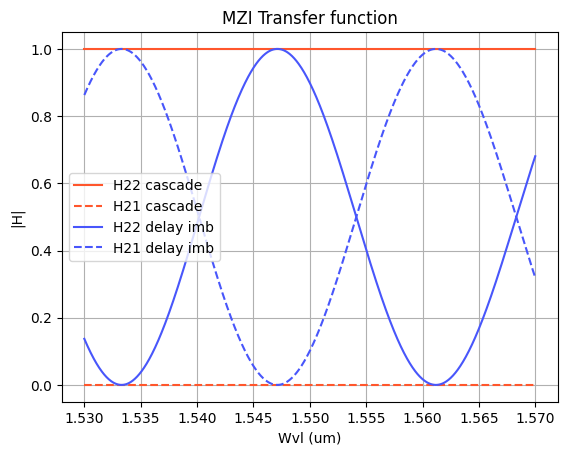

In [99]:
K_c = 0.5
K_d = 0.5
Lu = 25; # um
Ld = 5; # um

wvl0 = SOI[:, 0] # wavelength
neffu0 = SOI[:, 3] #balanced configuration // (neff TE mode) up
neffd0 = SOI[:, 3] #balanced configuration // (neff TE mode) down

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)

mzi_cascade = mzi_2(wl=wvl,
            coup_a={"coupling":K_a},
            wvg_u1={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d1={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
            coup_b={"coupling":K_b},
            wvg_u2={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d2={"wl":wvl, "neff":neffd, "length": Lu, "loss":alphad},
            coup_c={"coupling":K_c},
            wvg_u3={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d3={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
            coup_d={"coupling":K_d},

            )

# h00 = mzi_cascade["in0", "out0"]
# h01 = mzi_cascade["in0", "out1"]
h11 = mzi_cascade["in1", "out1"]
h10 = mzi_cascade["in1", "out0"]


# Plot
plt.figure()
plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"H22 cascade")
plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"H21 cascade")
plt.plot(wvl, H22_unb_delay, linestyle='-', color=color[1], label='H22 delay imb')
plt.plot(wvl, H21_unb_delay, linestyle='--', color=color[1], label='H21 delay imb')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('MZI Transfer function')
plt.legend()
plt.grid(True)
plt.show()

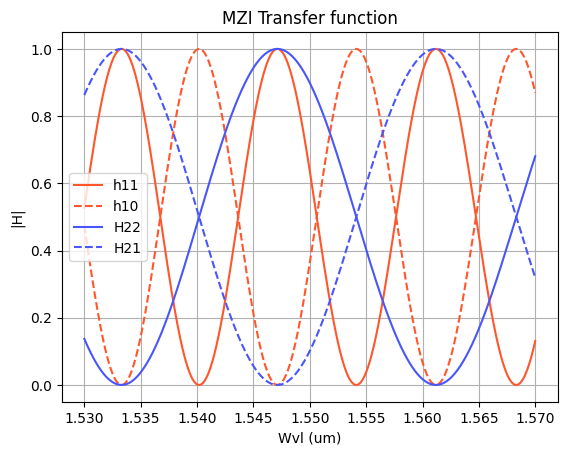

In [100]:
K_c = 0.5
K_d = 0.5
Lu = 25; # um
Ld = 5; # um

mzi_cascade = mzi_2(wl=wvl,
            coup_a={"coupling":K_a},
            wvg_u1={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d1={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
            coup_b={"coupling":K_b},
            wvg_u2={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d2={"wl":wvl, "neff":neffd, "length": Lu, "loss":alphad},
            coup_c={"coupling":K_c},
            wvg_u3={"wl":wvl, "neff":neffu, "length": Ld, "loss":alphau},
            wvg_d3={"wl":wvl, "neff":neffd, "length": Lu, "loss":alphad},
            coup_d={"coupling":K_d},

            )

h00 = mzi_cascade["in0", "out0"]
h01 = mzi_cascade["in0", "out1"]
h11 = mzi_cascade["in1", "out1"]
h10 = mzi_cascade["in1", "out0"]


# Plot
plt.figure()
plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"h11")
plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"h10")
plt.plot(wvl, H22_unb_delay, linestyle='-', color=color[1], label='H22')
plt.plot(wvl, H21_unb_delay, linestyle='--', color=color[1], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('MZI Transfer function')
plt.legend()
plt.grid(True)
plt.show()